# Day 4 — Pricing Strategy, Category Revenue Modeling, User Sentiment & Interactive Dashboard

**Project**: Oasis Infobyte Data Analytics Internship · Task Level 2 (Task 4)  
**Deliverable Focus**: Task 4 Milestone 3 — Commercial Monetization, Multi-Engine Sentiment Analysis & Strategic Opportunity Modeling  

---

### 🎯 Day 4 Core Objectives & Checklist:
- [x] **Paid vs. Free Dynamics**: Quantify store catalog split (92.2% Free vs. 7.8% Paid); model price distribution across 5 tiers.
- [x] **Price Outlier Analysis**: Isolate ultra-high ticket luxury apps (.00 to .00) vs. mainstream utility pricing (<.00).
- [x] **Category Gross Revenue Modeling**: Estimate paid revenue using $\text{Gross Revenue} = \text{Price} \times \text{Installs}$; rank top monetizing categories.
- [x] **Multi-Engine Sentiment Analysis**: Score 29,692 user reviews with **VADER** and compare polarity, subjectivity, and agreement with **TextBlob**.
- [x] **Category Sentiment Aggregation**: Profile sentiment polarities across all 33 categories; isolate top delight vs. structural friction sectors.
- [x] **Multi-Dimensional Market Opportunity Matrix**: Synthesize ratings, revenue, installs, and sentiment into unified category Opportunity Scores (0–100).
- [x] **Strategic Quadrants & Interactive Dashboard**: Export 4 publication figures and an interactive Plotly bubble chart HTML dashboard.
- [x] **Developer Launch Playbooks**: Formulate 3 empirical, data-driven launch recommendations for software founders and engineering leaders.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Configure styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 11

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pricing_sentiment_analysis import (
    compute_pricing_distribution,
    compute_category_monetization,
    get_top_revenue_apps,
    compute_sentiment_scores,
    compute_sentiment_metrics,
    compute_category_sentiment_summary,
    compute_market_opportunity_matrix,
    generate_developer_recommendations,
    plot_pricing_distributions,
    plot_category_revenue,
    plot_sentiment_analysis,
    plot_market_opportunity_bubble,
    create_interactive_plotly_dashboard
)

# Load cleaned datasets
apps_df = pd.read_csv(PROJECT_ROOT / "Data" / "cleaned_googleplaystore.csv")
reviews_df = pd.read_csv(PROJECT_ROOT / "Data" / "cleaned_user_reviews.csv")

print(f"Loaded {len(apps_df):,} apps across {apps_df['Category'].nunique()} categories.")
print(f"Loaded {len(reviews_df):,} user reviews across {reviews_df['App'].nunique()} unique apps.")


Loaded 9,659 apps across 33 categories.
Loaded 29,692 user reviews across 865 unique apps.


---
## 1. Paid vs. Free Market Structure & Price Distribution

In mobile app ecosystems, the barrier to initial download is the primary friction point. Here, we analyze the distribution between Free and Paid apps, evaluate price elasticity tiers, and analyze extreme price outliers ($400 "I am Rich" apps).


GOOGLE PLAY STORE PRICING STRUCTURE
Total Apps Catalog      : 9,659
Free Apps               : 8,905 (92.19%)
Paid Apps               : 754 (7.81%)
Paid Price Mean         : $14.06
Paid Price Median       : $2.99
Paid Price IQR (Q25-Q75): [$1.49, $4.99]
Paid Price Range        : [$0.99, $400.00]
Luxury Outliers (>= $30): 29 apps

Price Tier Breakdown:


,Tier,App Count,Share (%)
0,Tier 1: $0.99 - $1.99,280,37.1%
1,Tier 2: $2.00 - $4.99,316,41.9%
2,Tier 3: $5.00 - $9.99,83,11.0%
3,Tier 4: $10.00 - $29.99,46,6.1%
4,Tier 5: $30.00+ (Luxury/Outlier),29,3.8%


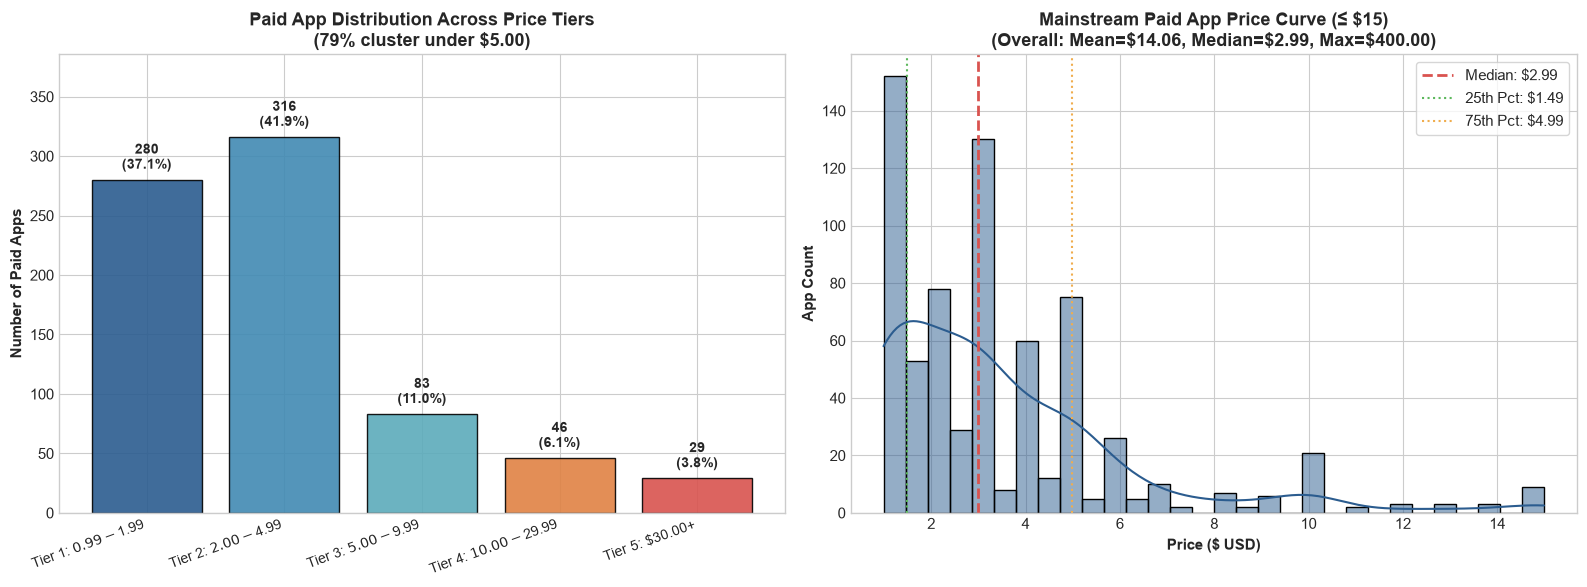

In [2]:
pricing_stats = compute_pricing_distribution(apps_df)

print("=" * 60)
print("GOOGLE PLAY STORE PRICING STRUCTURE")
print("=" * 60)
print(f"Total Apps Catalog      : {pricing_stats['total_apps']:,}")
print(f"Free Apps               : {pricing_stats['free_apps']:,} ({pricing_stats['free_percentage']:.2f}%)")
print(f"Paid Apps               : {pricing_stats['paid_apps']:,} ({pricing_stats['paid_percentage']:.2f}%)")
print(f"Paid Price Mean         : ${pricing_stats['paid_mean']:.2f}")
print(f"Paid Price Median       : ${pricing_stats['paid_median']:.2f}")
print(f"Paid Price IQR (Q25-Q75): [${pricing_stats['paid_q25']:.2f}, ${pricing_stats['paid_q75']:.2f}]")
print(f"Paid Price Range        : [${pricing_stats['paid_min']:.2f}, ${pricing_stats['paid_max']:.2f}]")
print(f"Luxury Outliers (>= $30): {pricing_stats['outlier_count_gte_30']} apps")

print("\nPrice Tier Breakdown:")
tier_summary_df = pd.DataFrame([
    {"Tier": k, "App Count": v["count"], "Share (%)": f"{v['percentage']:.1f}%"}
    for k, v in pricing_stats["tier_breakdown"].items()
])
display(tier_summary_df)

fig_pricing = plot_pricing_distributions(apps_df)
plt.show()


---
## 2. Category-Level Gross Revenue Modeling & Top Earners

Using the industry proxy metric:
$$\text{Estimated Gross Revenue} = \text{Price} \times \text{Installs}$$
we quantify which app categories capture the highest paid monetization volume and identify the top individual paid software titles.


Top 10 Categories by Estimated Gross Revenue:


,Category,Total_Apps,Paid_Apps,Paid_Share_Pct,Estimated_Revenue,Revenue_Per_Paid_App,Revenue_Share_Pct
0,FAMILY,1874,184,9.82,1.156748e+08,628667.64,39.73
1,LIFESTYLE,369,19,5.15,5.758394e+07,3030733.65,19.78
2,GAME,946,82,8.67,4.068864e+07,496202.89,13.98
3,FINANCE,345,17,4.93,2.572668e+07,1513334.06,8.84
4,PHOTOGRAPHY,281,19,6.76,8.547768e+06,449882.51,2.94
5,PERSONALIZATION,376,81,21.54,6.796948e+06,83912.93,2.33
6,MEDICAL,395,82,20.76,5.956237e+06,72637.03,2.05
7,TOOLS,829,78,9.41,5.464821e+06,70061.80,1.88
8,SPORTS,325,24,7.38,4.706212e+06,196092.16,1.62
9,PRODUCTIVITY,374,28,7.49,4.313375e+06,154049.11,1.48



Top 10 Highest Grossing Paid Apps:


,App,Category,Price,Installs,Estimated_Revenue,Rating,Reviews
0,Minecraft,FAMILY,6.99,10000000,69900000.0,4.5,2376564
1,I am rich,LIFESTYLE,399.99,100000,39999000.0,3.8,3547
2,I Am Rich Premium,FINANCE,399.99,50000,19999500.0,4.1,1867
3,Hitman Sniper,GAME,0.99,10000000,9900000.0,4.6,408292
4,Grand Theft Auto: San Andreas,GAME,6.99,1000000,6990000.0,4.4,348962
5,Facetune - For Free,PHOTOGRAPHY,5.99,1000000,5990000.0,4.4,49553
6,Sleep as Android Unlock,LIFESTYLE,5.99,1000000,5990000.0,4.5,23966
7,DraStic DS Emulator,GAME,4.99,1000000,4990000.0,4.6,87766
8,I'm Rich - Trump Edition,LIFESTYLE,400.00,10000,4000000.0,3.6,275
9,💎 I'm rich,LIFESTYLE,399.99,10000,3999900.0,3.8,718


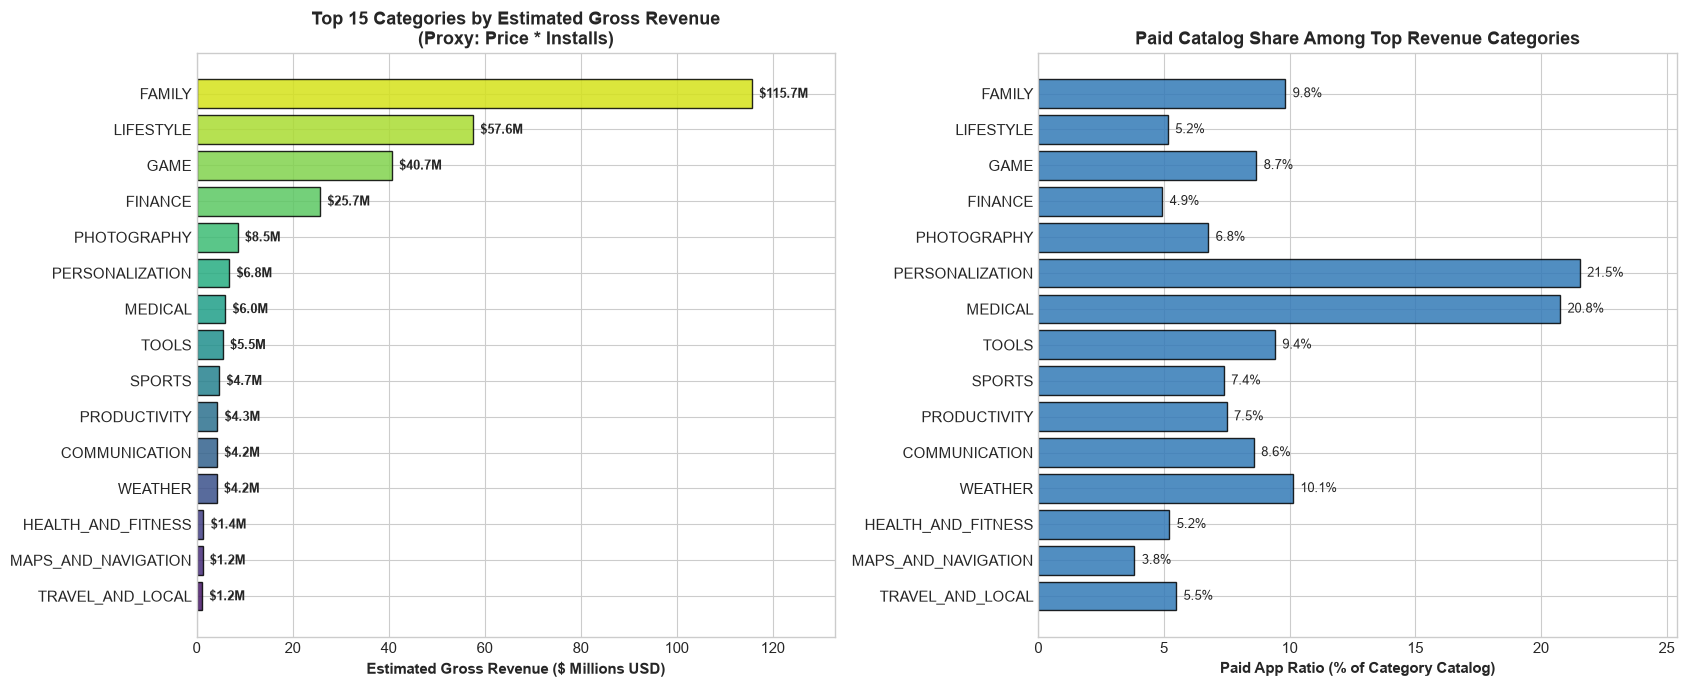

In [3]:
monetization_df = compute_category_monetization(apps_df)
top_revenue_apps = get_top_revenue_apps(apps_df, n=15)

print("Top 10 Categories by Estimated Gross Revenue:")
display(monetization_df[[
    "Category", "Total_Apps", "Paid_Apps", "Paid_Share_Pct",
    "Estimated_Revenue", "Revenue_Per_Paid_App", "Revenue_Share_Pct"
]].head(10))

print("\nTop 10 Highest Grossing Paid Apps:")
display(top_revenue_apps.head(10))

fig_rev = plot_category_revenue(monetization_df)
plt.show()


---
## 3. Multi-Engine Sentiment Analysis (VADER & TextBlob)

To evaluate user satisfaction beyond simple 1-5 star ratings, we analyze 29,692 user reviews using two distinct Natural Language Processing approaches:
1. **TextBlob**: PatternAnalyzer rule-based lexicon computing polarity $[-1.0, +1.0]$ and subjectivity $[0.0, 1.0]$.
2. **NLTK VADER**: Valence Aware Dictionary and sEntiment Reasoner, specifically calibrated for social and mobile review vernacular, computing compound polarity scores.


MULTI-ENGINE SENTIMENT ANALYSIS BENCHMARKS
Total Reviews Scored      : 29,692
VADER vs TextBlob Match   : 22,604 (76.1% agreement)
Mean TextBlob Polarity    : +0.189
Mean VADER Compound Score : +0.337
VADER Sentiment Split     : Positive 67.8% | Neutral 12.5% | Negative 19.7%

Top 5 Highest Sentiment Categories (Highest Delight):


,Category,Review_Count,Reviewed_Apps,Mean_VADER_Compound,Mean_TextBlob_Polarity,Mean_Subjectivity,VADER_Positive_Pct,VADER_Negative_Pct,VADER_Neutral_Pct,TextBlob_Positive_Pct,TextBlob_Negative_Pct
0,COMICS,45,2,0.536,0.450,0.571,86.7,2.2,11.1,86.7,2.2
1,AUTO_AND_VEHICLES,283,8,0.510,0.343,0.525,82.0,4.9,13.1,81.3,6.0
2,HEALTH_AND_FITNESS,1621,40,0.479,0.294,0.513,77.9,13.6,8.5,77.9,11.0
3,PARENTING,256,8,0.453,0.313,0.501,73.0,10.9,16.0,70.7,9.0
4,EDUCATION,519,19,0.449,0.298,0.508,76.3,11.9,11.8,75.3,12.1



Bottom 5 Lowest Sentiment Categories (Highest Friction):


,Category,Review_Count,Reviewed_Apps,Mean_VADER_Compound,Mean_TextBlob_Polarity,Mean_Subjectivity,VADER_Positive_Pct,VADER_Negative_Pct,VADER_Neutral_Pct,TextBlob_Positive_Pct,TextBlob_Negative_Pct
28,BEAUTY,317,6,0.247,0.200,0.493,60.6,19.9,19.6,55.5,18.9
29,ENTERTAINMENT,701,21,0.232,0.132,0.483,57.9,27.1,15.0,60.8,24.8
30,NEWS_AND_MAGAZINES,733,24,0.205,0.153,0.474,57.6,25.5,16.9,60.7,23.3
31,VIDEO_PLAYERS,326,9,0.185,0.136,0.478,55.8,31.6,12.6,56.7,25.5
32,SOCIAL,661,18,0.168,0.108,0.478,54.9,31.6,13.5,55.5,28.7


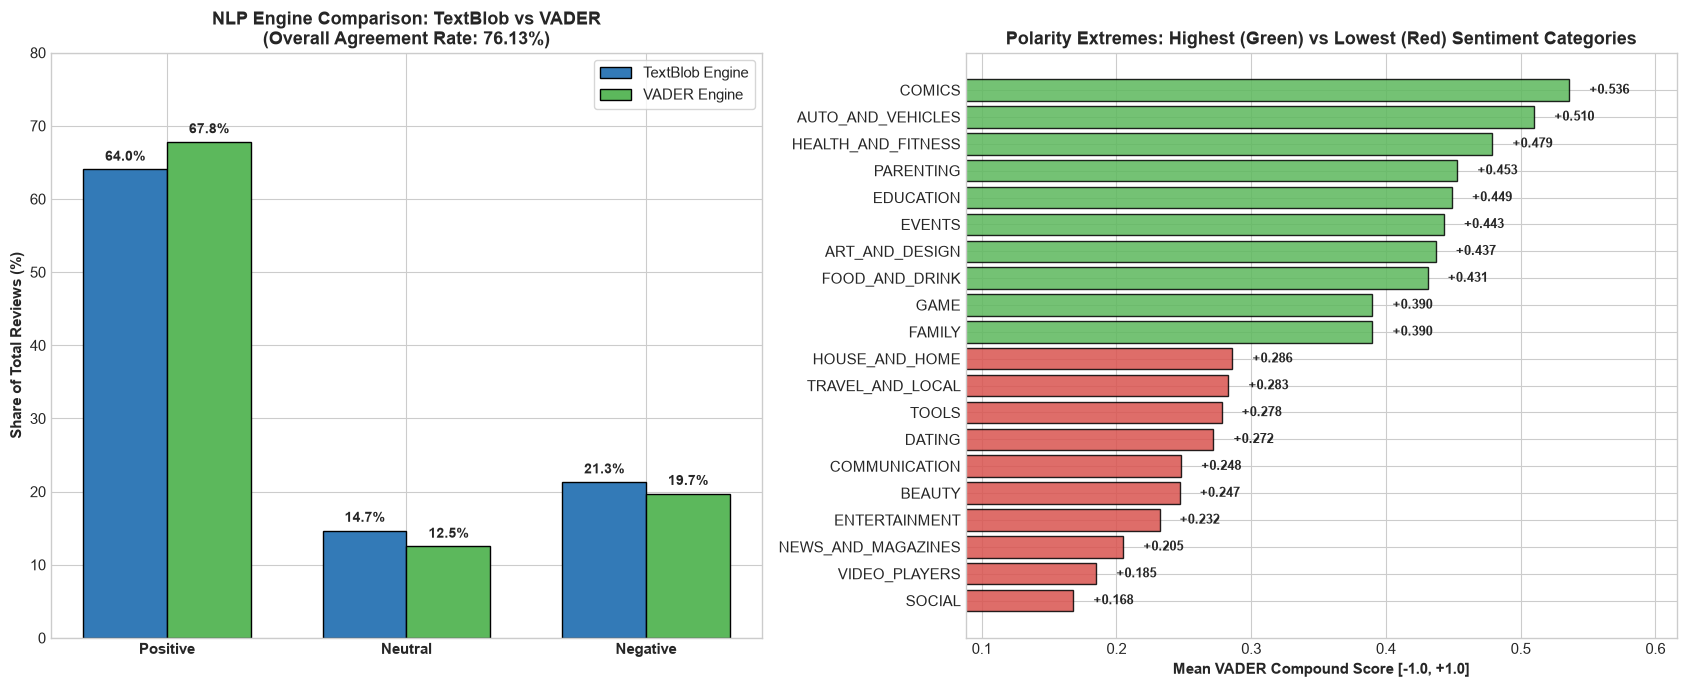

In [4]:
scored_reviews = compute_sentiment_scores(reviews_df)
sentiment_metrics = compute_sentiment_metrics(scored_reviews)
cat_sentiment_df = compute_category_sentiment_summary(scored_reviews, apps_df)

print("=" * 60)
print("MULTI-ENGINE SENTIMENT ANALYSIS BENCHMARKS")
print("=" * 60)
print(f"Total Reviews Scored      : {sentiment_metrics['total_reviews']:,}")
print(f"VADER vs TextBlob Match   : {sentiment_metrics['agreement_count']:,} ({sentiment_metrics['agreement_percentage']:.1f}% agreement)")
print(f"Mean TextBlob Polarity    : {sentiment_metrics['textblob_polarity_mean']:+.3f}")
print(f"Mean VADER Compound Score : {sentiment_metrics['vader_compound_mean']:+.3f}")
print(f"VADER Sentiment Split     : Positive {sentiment_metrics['vader_percentage'].get('Positive', 0):.1f}% | "
      f"Neutral {sentiment_metrics['vader_percentage'].get('Neutral', 0):.1f}% | "
      f"Negative {sentiment_metrics['vader_percentage'].get('Negative', 0):.1f}%")

print("\nTop 5 Highest Sentiment Categories (Highest Delight):")
display(cat_sentiment_df.head(5))

print("\nBottom 5 Lowest Sentiment Categories (Highest Friction):")
display(cat_sentiment_df.tail(5))

fig_sentiment = plot_sentiment_analysis(scored_reviews, cat_sentiment_df)
plt.show()


---
## 4. Multi-Dimensional Market Opportunity Matrix & Quadrant Modeling

We synthesize category ratings, install volumes, monetization revenue, and sentiment polarities into a single **Market Opportunity Matrix** evaluated across 4 strategic quadrants:
- **Quadrant I**: High Rating & High Sentiment (**Delight Sweet Spot**)
- **Quadrant II**: High Rating & Lower Sentiment (**Latent Review Friction**)
- **Quadrant III**: Lower Rating & Higher Sentiment (**Niche Execution Gaps**)
- **Quadrant IV**: Lower Rating & Lower Sentiment (**Red Ocean / Churn Risk**)


Top 10 Categories by Opportunity Score (0 to 100):


,Category,Opportunity_Score,Strategic_Quadrant,Mean_Rating,Mean_VADER_Compound,Estimated_Revenue,Total_Apps,Total_Installs
0,EDUCATION,76.9,Quadrant I: High Satisfaction / High Delight,4.354717,0.449,408980.00,107,189952000
1,PARENTING,76.8,Quadrant I: High Satisfaction / High Delight,4.300000,0.453,249959.00,60,31521110
2,ART_AND_DESIGN,75.9,Quadrant I: High Satisfaction / High Delight,4.359322,0.437,31840.00,61,113238100
3,EVENTS,72.7,Quadrant I: High Satisfaction / High Delight,4.435556,0.443,109.99,64,15973161
4,AUTO_AND_VEHICLES,72.3,Quadrant I: High Satisfaction / High Delight,4.190411,0.510,100148.50,85,53130211
5,HEALTH_AND_FITNESS,69.4,Quadrant I: High Satisfaction / High Delight,4.243033,0.479,1426068.90,288,1144022512
6,FOOD_AND_DRINK,64.6,Quadrant III: High Review Sentiment / Structur...,4.171277,0.431,284400.00,112,211798751
7,PERSONALIZATION,64.5,Quadrant I: High Satisfaction / High Delight,4.332215,0.352,6796947.56,376,1532494782
8,BOOKS_AND_REFERENCE,64.4,Quadrant I: High Satisfaction / High Delight,4.344970,0.377,90226.74,222,1665969576
9,WEATHER,63.9,Quadrant II: High Rating / Latent Review Friction,4.243056,0.305,4181380.00,79,361100520



Category Count by Strategic Quadrant:


Strategic_Quadrant
Quadrant I: High Satisfaction / High Delight             12
Quadrant IV: Red Ocean / High User Friction              11
Quadrant III: High Review Sentiment / Structural Gaps     5
Quadrant II: High Rating / Latent Review Friction         5
Name: count, dtype: int64

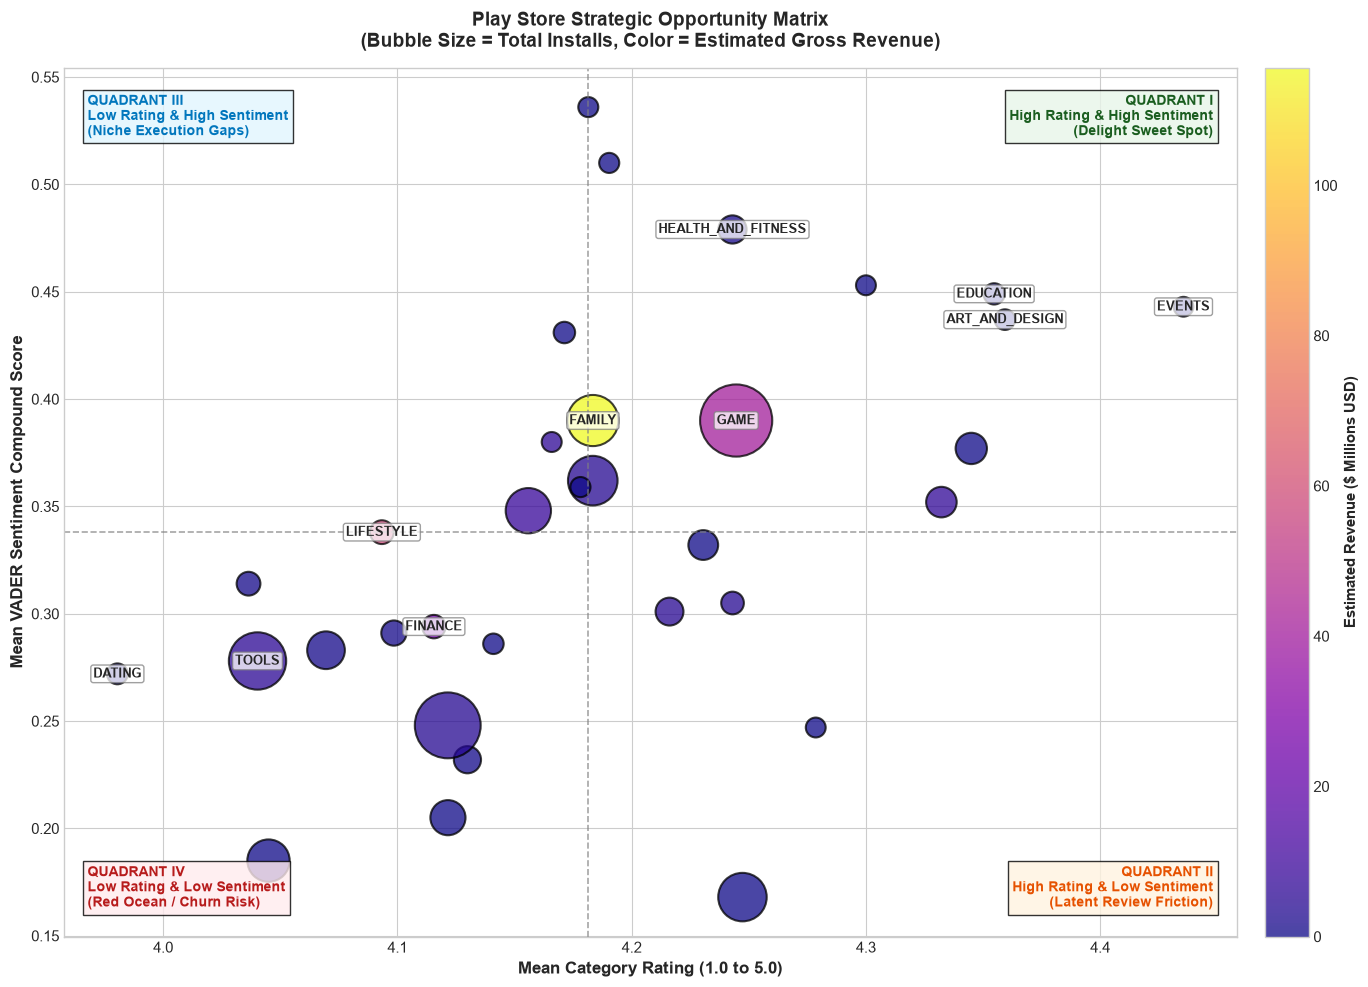

In [5]:
opportunity_df = compute_market_opportunity_matrix(apps_df, monetization_df, cat_sentiment_df)

print("Top 10 Categories by Opportunity Score (0 to 100):")
display(opportunity_df[[
    "Category", "Opportunity_Score", "Strategic_Quadrant", "Mean_Rating",
    "Mean_VADER_Compound", "Estimated_Revenue", "Total_Apps", "Total_Installs"
]].head(10))

print("\nCategory Count by Strategic Quadrant:")
display(opportunity_df["Strategic_Quadrant"].value_counts())

fig_bubble = plot_market_opportunity_bubble(opportunity_df)
plt.show()


---
## 5. Interactive Plotly Market Intelligence Dashboard

The interactive Plotly bubble chart enables dynamic inspection of market parameters, hovering over individual categories to reveal granular metrics: installs in billions, estimated revenue, user rating, and positive review ratios.


In [6]:
plotly_fig = create_interactive_plotly_dashboard(
    opportunity_df,
    output_path=str(PROJECT_ROOT / "reports" / "figures" / "08_market_opportunity_dashboard.html")
)
plotly_fig.show()


---
## 6. Strategic Developer Launch Recommendations

Synthesizing empirical findings from Day 1 (data pipeline), Day 2 (market structure & correlations), and Day 4 (pricing, revenue & sentiment):


In [7]:
recommendations = generate_developer_recommendations(opportunity_df)

for rec in recommendations:
    print("=" * 70)
    print(f"[{rec['recommendation_id']}] {rec['title']}")
    print(f"Target Sectors: {rec['category_targets']}")
    print("=" * 70)
    print(f"Empirical Rationale:\n{rec['empirical_rationale']}\n")
    print(f"Actionable Playbook:\n{rec['actionable_playbook']}\n")


[REC-01] Target High-Delight Niche Sectors with Upfront Paid Pricing
Target Sectors: EVENTS, ART_AND_DESIGN, PARENTING, AUTO_AND_VEHICLES
Empirical Rationale:
Categories like EVENTS (mean rating 4.44, VADER compound +0.47) and ART_AND_DESIGN (mean rating 4.36, VADER compound +0.42) have exceptionally low market crowding (<65 apps each) yet boast top-decile user sentiment. Low keyword competition dramatically reduces App Store Optimization (ASO) customer acquisition costs (CAC). Furthermore, paid apps in these utility niches convert at higher conversion rates without user backlash against ads.

Actionable Playbook:
Launch specialized, single-purpose workflow tools priced at $1.99 - $3.99 upfront or $9.99/yr subscription. Focus on pristine UX without invasive ad networks to preserve the high organic sentiment baseline.

[REC-02] Adopt Freemium-First Monetization in Massive Scale Categories
Target Sectors: GAME, FAMILY, PHOTOGRAPHY, TOOLS
Empirical Rationale:
While FAMILY ($115.67M estima

---
## 7. Deliverables & Artifact Audit

All generated reports, data summaries, high-resolution figures, and interactive dashboards are exported to the `reports/` directory.


In [8]:
expected_artifacts = [
    PROJECT_ROOT / "reports" / "category_revenue_summary.csv",
    PROJECT_ROOT / "reports" / "top_revenue_apps_summary.csv",
    PROJECT_ROOT / "reports" / "category_sentiment_summary.csv",
    PROJECT_ROOT / "reports" / "market_opportunity_matrix.csv",
    PROJECT_ROOT / "reports" / "figures" / "05_paid_vs_free_pricing.png",
    PROJECT_ROOT / "reports" / "figures" / "06_category_revenue_estimation.png",
    PROJECT_ROOT / "reports" / "figures" / "07_sentiment_distribution.png",
    PROJECT_ROOT / "reports" / "figures" / "08_market_bubble_dashboard.png",
    PROJECT_ROOT / "reports" / "figures" / "08_market_opportunity_dashboard.html"
]

print("Artifact Verification:")
for f in expected_artifacts:
    status = "EXISTS" if f.exists() else "MISSING"
    size_kb = f.stat().st_size / 1024 if f.exists() else 0
    print(f"[{status}] {f.name:<45} ({size_kb:>8.1f} KB)")


Artifact Verification:
[EXISTS] category_revenue_summary.csv                  (     2.6 KB)
[EXISTS] top_revenue_apps_summary.csv                  (     1.2 KB)
[EXISTS] category_sentiment_summary.csv                (     2.2 KB)
[EXISTS] market_opportunity_matrix.csv                 (     5.8 KB)
[EXISTS] 05_paid_vs_free_pricing.png                   (   296.6 KB)
[EXISTS] 06_category_revenue_estimation.png            (   354.6 KB)
[EXISTS] 07_sentiment_distribution.png                 (   361.9 KB)
[EXISTS] 08_market_bubble_dashboard.png                (   517.0 KB)
[EXISTS] 08_market_opportunity_dashboard.html          (    31.9 KB)
